# TD 4: Bayesian inference with Metropolis sampling: From noisy measurements to Gravitational waves.

The aim is to apply the statistical tools from the course to a real dataset. First, we infer a slope and an intercept from artificial noisy measurements. Then, we reuse the same reasoning and sampler for the gravitational-wave event GW150914.

The physical model and data preparation in Part 2 are supplied. You do not need to derive the gravitational-wave model or understand every line of its preparation code. You need to understand what data it returns, which parameters the model uses, and how the noise enters the likelihood. We thank Eric Chassande-Mottin (laboratoire AstroParticule et Cosmologie (APC) Paris) for his help on accessing and treating the data on the first iterations of the course.

Across the two sessions we use $d$ for data, $\theta$ for parameters, $\mathcal L(d\mid\theta)$ for the likelihood, $\pi(\theta)$ for the prior, and $p(\theta\mid d)$ for the posterior. A chain is the sequence of parameter values generated by the sampler.


**Requirements:** NumPy, SciPy, Matplotlib, `corner`, PyCBC and LALSuite. If necessary, install them in a separate cell with `%pip install numpy scipy matplotlib corner pycbc lalsuite`, then restart the kernel. Keep the two `GW150914_*_raw.npz` files beside this notebook. They allow Part 2 to run without downloading data during class.



In [1]:
import numpy as np
from matplotlib import pyplot as plt
import corner
from pathlib import Path
from time import perf_counter

plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.25})

## Part 1 — Artificial data

The model is a straight line:

$$
f(x_n,\theta)=a_1x_n+a_2,\qquad \theta=(a_1,a_2).
$$

We consider $M=200$ observations with $x_n=n/M$, $n=0,\ldots,M-1$, and true parameters $\theta^*=(30,800)$:

$$
d_n=f(x_n,\theta^*)+\epsilon_n,
\qquad \epsilon_n\sim\mathcal N(0,\sigma_n^2).
$$

The noises are independent, but their standard deviations differ: $\sigma_n=e^{\alpha_n}$ with $\alpha_n$ uniform on $[-2,6]$. This gives log-uniform noise scales. Once generated, the $\sigma_n$ are treated as known.

The aim of the first part of the tutorial will be to infer the parameters $a_1^*$ and $a_2^*$ from the measures of $d_n$ knowing the standard deviations $\sigma_n$. As we will see later, this model shares many similarities with the one we will be using for the second part: two parameters and different but fixed standard deviations.


### Q0. Generate and inspect the data

Generate and plot the data and noise scales.

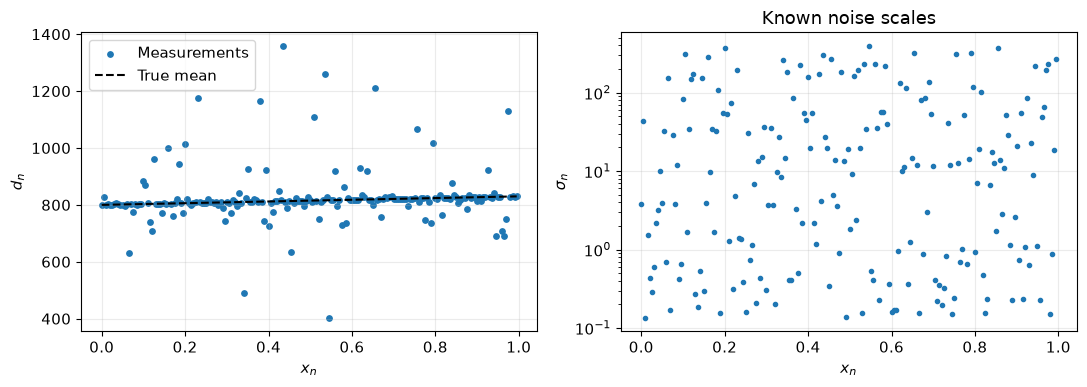

In [2]:
rng_data = np.random.RandomState(1)
M = 200
x = np.arange(M) / M
theta_true = np.array([30.0, 800.0])
sigma_n = np.exp(rng_data.uniform(-2, 6, M))
f_x = theta_true[0] * x + theta_true[1]
d = f_x + rng_data.normal(0, sigma_n)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(x, d, s=15, label="Measurements")
axes[0].plot(x, f_x, "k--", label="True mean")
axes[0].set(xlabel="$x_n$", ylabel="$d_n$")
axes[0].legend()
axes[1].semilogy(x, sigma_n, ".")
axes[1].set(xlabel="$x_n$", ylabel=r"$\sigma_n$", title="Known noise scales")
fig.tight_layout()
plt.show()

### Q1. Log likelihood

Write the log-likelihood distribution of the signal $d=(d_n)_{n=1,\ldots, M}$ given the parameters $\theta$ of the model, the gaussian noise and the observations. What simplifying assumptions can you make?

Write a function returning the parameter-dependent part of the log-likelihood



For one observation, the model predicts a Gaussian density centered at $a_1x_n+a_2$. Independence makes the full likelihood a product. Taking its logarithm gives

$$
\log\mathcal L(d\mid\theta)
=-\frac12\sum_n\left[\frac{(d_n-a_1x_n-a_2)^2}{\sigma_n^2}
+\log(2\pi\sigma_n^2)\right].
$$

The normalization term can be omitted here because the noise scales are fixed. It cannot be dropped when **inferring** those noise scales. A smaller noise variance gives a larger penalty for the same residual.

In [3]:
def loglike_linear(theta):
    a1, a2 = theta
    residual = (d - a1 * x - a2) / sigma_n
    return -0.5 * np.sum(residual ** 2)

### Q2. Add a prior and obtain the posterior

Write the posterior probability for the parameters given the data.  Consider two priors:
- **Positive:** both parameters are nonnegative.
- **Interval:** $20\le a_1\le100$ and $300\le a_2\le3000$.

Write the log posterior using your likelihood. (return a constant inside the allowed region and $-\infty$ outside)



Bayes' rule gives

$$
p(\theta\mid d)\propto\mathcal L(d\mid\theta)\pi(\theta).
$$

For sampling, we need only

$$
\log p(\theta\mid d)=\log\mathcal L(d\mid\theta)+\log\pi(\theta)+\text{constant}.
$$

Notice that the positive-only constant prior is improper as it has infinite prior mass. The posterior, however, is proper (i.e. normalizable).

In [4]:
def logprior_linear(theta, prior="positive"):
    a1, a2 = theta
    if prior == "positive":
        inside = a1 >= 0 and a2 >= 0
    elif prior == "interval":
        inside = 20 <= a1 <= 100 and 300 <= a2 <= 3000
    else:
        raise ValueError("Choose 'positive' or 'interval'.")
    return 0.0 if inside else -np.inf

def logpost_linear(theta, prior="positive"):
    lp = logprior_linear(theta, prior)
    return lp + loglike_linear(theta) if np.isfinite(lp) else -np.inf

### Q3(i). Implement a simple Metropolis sampler

At the current state $\theta$, propose

$$
\theta'=\theta+\eta,
\qquad \eta_j\sim\mathcal N(0,s_j^2).
$$

The proposal is symmetric: proposing the reverse move has the same density. Therefore accept with probability

$$
A=\min\left(1,\frac{p(\theta'\mid d)}{p(\theta\mid d)}\right).
$$

Equivalently, draw $u$ uniformly on $(0,1)$ and accept when

$$
\log u<\min\{0,\log p(\theta'\mid d)-\log p(\theta\mid d)\}.
$$


Complete this algorithm. Store the current state after every step, including rejections. You can start with $s_1 = 1$ for the first parameter $a_1$ and $s_2 =10$ for $a_2$. Notice that these values are only a choice.


In [5]:
# Reusable sampler: run this definition again if starting Part 2 in a fresh kernel.
def metropolis(log_probability, theta0, etas, n_steps, seed=0):
    rng = np.random.default_rng(seed)
    theta = np.array(theta0, dtype=float)
    current_logp = log_probability(theta)
    if not np.isfinite(current_logp):
        raise ValueError("Start inside the prior, with a finite log probability.")

    chain = np.empty((n_steps, len(theta)))
    logp = np.empty(n_steps)
    chain[0], logp[0] = theta, current_logp
    accepted = 0

    for k in range(1, n_steps):
        proposal = theta + rng.normal(0, etas, size=len(theta))
        proposed_logp = log_probability(proposal)
        if np.isfinite(proposed_logp) and np.log(max(rng.random(), 1e-300)) < min(0.0, proposed_logp - current_logp):
            theta, current_logp = proposal, proposed_logp
            accepted += 1
        chain[k], logp[k] = theta, current_logp

    return chain, logp, accepted / (n_steps - 1)

### Choosing the proposal size

First try the original proposal scales $(1,10)$ for a short run. Then use smaller scales $(0.1,0.05)$ for the main run.

Compare the acceptance fractions and movement of the chains. Explain why proposal scales should be related to the posterior's width rather than the parameter's absolute value.

Plot the log-probability as a function of Monte-Carlo Step. Compare to the log-likelihood with the true parameters.

In [19]:
# bad sampling
bad_chain, bad_logp, bad_acceptance = metropolis(
    logpost_linear, [0, 0], [1, 10], 3000, seed=10)

# better sampling
N_LINEAR, START_FROM = 20000, 2000
chain_positive, logp_positive, acceptance_positive = metropolis(
    logpost_linear, [28, 801], [0.1, 0.05], N_LINEAR, seed=11)
samples_positive = chain_positive[START_FROM:]

print(f"Original proposal acceptance: {bad_acceptance:.1%}")
print(f"Smaller proposal acceptance:  {acceptance_positive:.1%}")

Original proposal acceptance: 5.0%
Smaller proposal acceptance:  40.6%


In [20]:
# Reusable plotting and summary helpers.
def plot_chain(chain, logp, labels):
    fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
    for j in range(2):
        axes[j].plot(chain[:, j], lw=0.6)
        axes[j].set_ylabel(labels[j])
    axes[2].plot(logp, lw=0.6)
    axes[2].set(xlabel="Metropolis step", ylabel="Log posterior")
    fig.tight_layout()
    plt.show()

def summarize(samples, labels):
    for j, label in enumerate(labels):
        mean = samples[:, j].mean()
        sd = samples[:, j].std(ddof=1)
        low, high = np.quantile(samples[:, j], [0.05, 0.95])
        print(f"{label}: mean {mean:.4f}, SD {sd:.4f}, variance {sd**2:.4f}; "
              f"90% interval [{low:.4f}, {high:.4f}]")

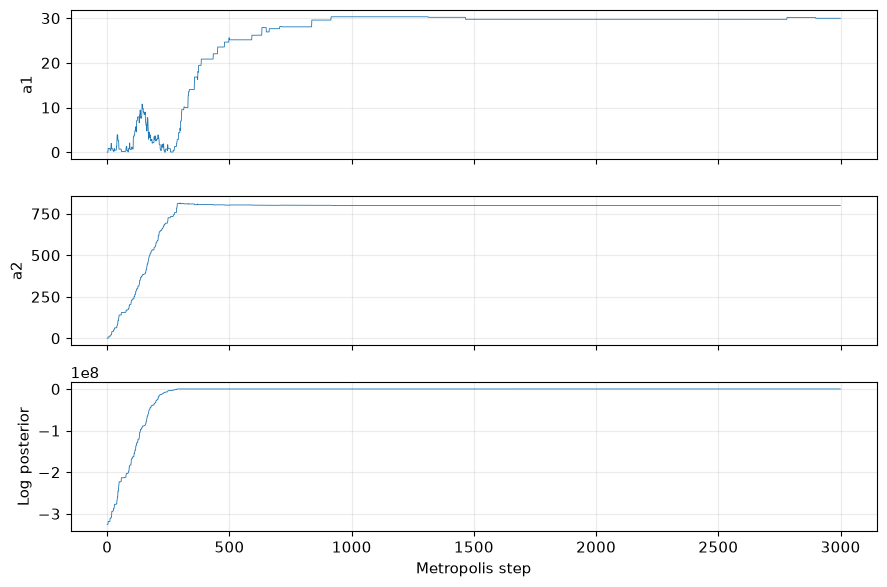

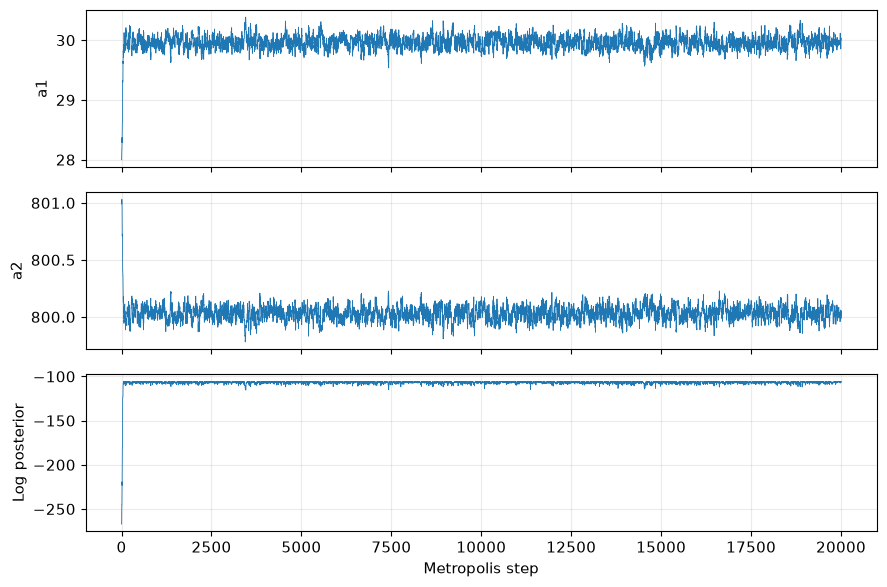

Log likelihood at the generating truth: -105.8317911363309


In [21]:
plot_chain(bad_chain, bad_logp, ["a1", "a2"])
plot_chain(chain_positive, logp_positive, ["a1", "a2"])
print("Log likelihood at the generating truth:", loglike_linear(theta_true))


Very large proposals are usually rejected. Very small proposals can be accepted often but move slowly.

### Q3(iii). Describe the posterior samples

Plot marginal histograms and the joint distribution with `corner`. Estimate the means and variances. Are the generating parameters in a plausible part of the distribution? Explain the slope–intercept correlation.



a1: mean 29.9628, SD 0.1065, variance 0.0114; 90% interval [29.7905, 30.1409]
a2: mean 800.0302, SD 0.0612, variance 0.0037; 90% interval [799.9297, 800.1326]


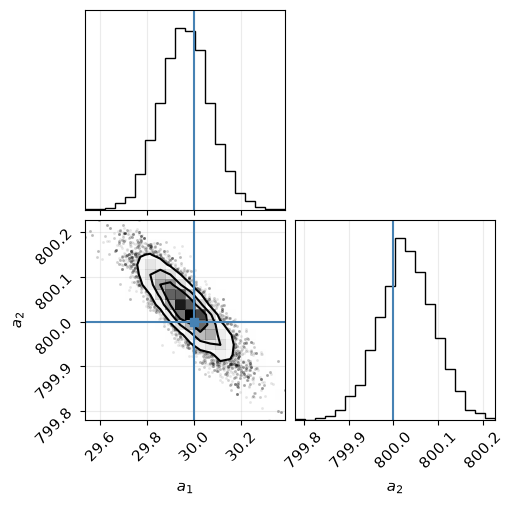

In [9]:
summarize(samples_positive, ["a1", "a2"])
corner.corner(samples_positive, labels=[r"$a_1$", r"$a_2$"], truths=theta_true)

plt.show()

Increasing the slope can be compensated by decreasing the intercept, giving a negative correlation.

### Q4. Compare the two priors

Rerun the sampler with the interval prior, a different starting point and a different seed. Compare its traces and parameter distributions with the first run.



Both prior boundaries are far from the likelihood peak, so the results should be similar. Small differences can come from finite, correlated samples. They do not automatically show an effect of the prior.

Repeating a run and looking for compatible summaries is a useful basic check. It does not prove that every important region was explored. If a retained trace still drifts or runs disagree substantially, investigate the proposal and run length before reporting uncertainty.

Interval-prior acceptance: 40.6%
a1: mean 29.9568, SD 0.1091, variance 0.0119; 90% interval [29.7803, 30.1391]
a2: mean 800.0335, SD 0.0640, variance 0.0041; 90% interval [799.9265, 800.1378]


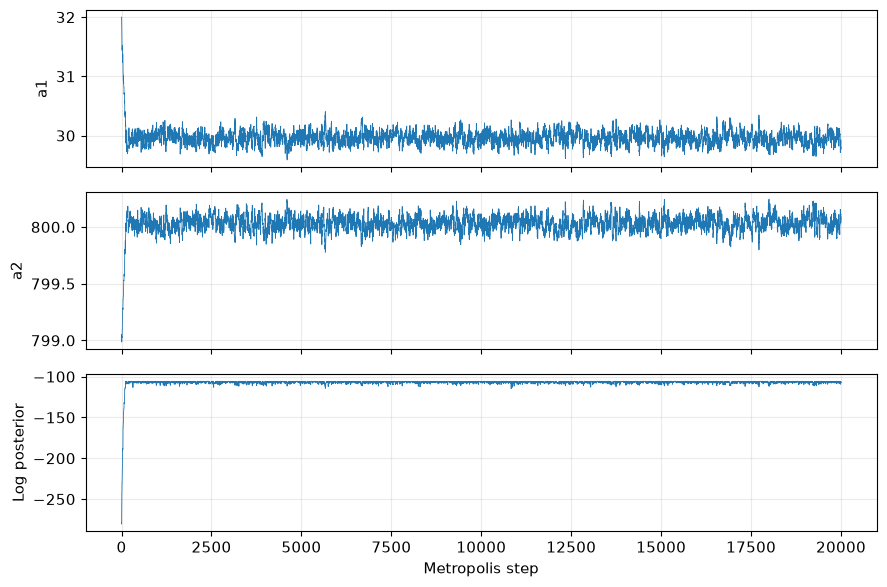

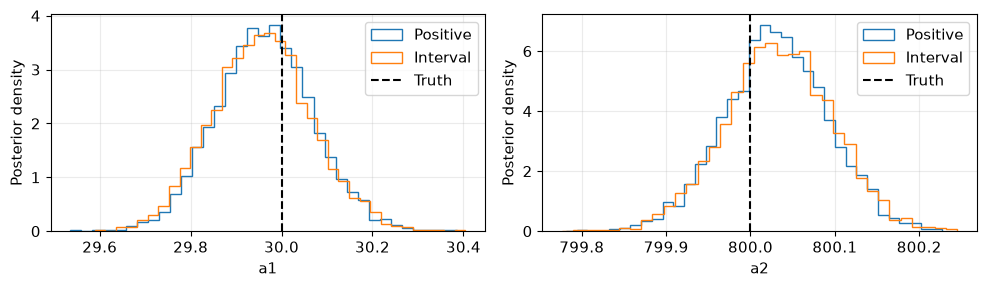

In [10]:
chain_interval, logp_interval, acceptance_interval = metropolis(
    lambda theta: logpost_linear(theta, "interval"),
    [32, 799], [0.1, 0.05], N_LINEAR, seed=12)
samples_interval = chain_interval[START_FROM:]

print(f"Interval-prior acceptance: {acceptance_interval:.1%}")
summarize(samples_interval, ["a1", "a2"])
plot_chain(chain_interval, logp_interval, ["a1", "a2"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for j, ax in enumerate(axes):
    ax.hist(samples_positive[:, j], bins=35, density=True, histtype="step", label="Positive")
    ax.hist(samples_interval[:, j], bins=35, density=True, histtype="step", label="Interval")
    ax.axvline(theta_true[j], color="k", ls="--", label="Truth")
    ax.set(xlabel=["a1", "a2"][j], ylabel="Posterior density")
    ax.legend()
fig.tight_layout()
plt.show()

### End of Session 1

Explain why noisy observations carry less weight and why Metropolis sometimes accepts lower-density proposals.

## Part 2 — Apply the same statistical method to GW150914

Gravitational waves are traveling perturbations in space-time, generated by cataclysmic events
in distant galaxies. The detection of gravitational waves has been a long-held goal of the physics community, and represents a further confirmation of Einstein’s Theory of General Relativity. On September 14, 2015, the two detectors of the Laser Interferometer Gravitational-wave Observatory (LIGO) observed a gravitational wave signal (GW150914) generated by the merger of two black holes. The LIGO detectors had been recently upgraded with new instrumentation and operating as Advanced LIGO, able to measure changes in the local shape of space-time with a precision better than one-thousandth the diameter of a proton. This discovery was
awarded by a nobel prize in 2017.

The L-shaped LIGO instruments consist of two perpendicular arms, each two of 4 kilometers long. A passing gravitational wave will alternately stretch one arm and squeeze the other, and then vice-versa; this generates an interference pattern at the readout port of the interferometer, which is measured by photo-detectors (Fig.1). Nice divulgation tutorials can be viewed in https://www.gw-openscience.org/path/.
The goal of this tutorial is to use Metropolis Sampling and Bayes Inference to measure the parameters of the binary black holes collision event detected by the gravitational wave GW150914, focusing on the inference of their masses and their lumonisity distance.
<!-- Eric Chassande-Mottin (laboratoire AstroParticule et Cosmologie (APC) Paris ) has kindly provided us the access to the data and to the signal pre-treatement.  -->



GW150914 was recorded by the Hanford (H1) and Livingston (L1) detectors. Each detector supplies a time series of strain, a dimensionless measure of deformation. We will use H1 for parameter inference and L1 for a visual comparison.

Our two model parameters are $\theta=(m,D)$: an assumed common component mass $m_1=m_2=m$ and a distance-like amplitude scale $D$. Masses are in solar masses and $D$ is in megaparsecs (Mpc).


The goal of this section is to follow previous steps implemented for artificial data and find distribution of the parameters $\theta$, their average values and variance, including the corner plots of distribution of parameters during the MC sampling.

![](Exp.png)

**Figure 1:**
Sketch and description of the experiment from [5]. As laser light bounces back and forth along
arms between its mirrors, LIGO senses gravitational waves as minuscule fluctuations in the lengths of the.


### Q5. Read the supplied inputs and inspect the data

| Supplied object | Meaning |
|---|---|
| `strain_H1`, `strain_L1` | Prepared detector time series |
| `d_gw` | Complex Fourier coefficients of an 8 s H1 interval |
| `psd_gw` | Noise power spectrum on the same frequency grid |
| `frequency`, `delta_f` | Frequencies and spacing between frequency bins |
| `gen_template(theta)` | Predicted complex Fourier coefficients for $(m,D)$ |

The preparation removes very low frequencies, downsamples the data and estimates the noise spectrum from intervals outside the event. 

The noise PSD $S(f)$ has units $\text{strain}^2/\text{Hz}$; its square root is the amplitude spectral density (ASD). A high PSD means that observations around that frequency are noisy. This replaces the known, observation-dependent noise variances in Part 1.

Inspect both time series and noise spectra. Why should two detectors have different noise weights? Why is it useful to estimate the noise outside the event?

In [11]:
# PROVIDED: prepare the two detectors and the Fourier inputs for inference.
import warnings
warnings.filterwarnings("ignore", message="Wswiglal-redir-stdio.*")
from scipy.signal import welch, windows
from pycbc.types import TimeSeries, FrequencySeries
from pycbc.filter import highpass, resample_to_delta_t
from pycbc.waveform import get_fd_waveform
import lal

EVENT_TIME, FS = 1126259462.4, 2048

def prepare_detector(name):
    with np.load(Path(f"GW150914_{name}_raw.npz"), allow_pickle=False) as saved:
        raw = TimeSeries(saved["strain"], delta_t=float(saved["delta_t"]),
                         epoch=float(saved["epoch"]))
    strain = resample_to_delta_t(highpass(raw, 15), 1 / FS).crop(2, 2)
    noise_estimates = []
    for start, end in [(EVENT_TIME - 10, EVENT_TIME - 2), (EVENT_TIME + 2, EVENT_TIME + 10)]:
        f_noise, noise = welch(np.asarray(strain.time_slice(start, end)), fs=FS,
                              nperseg=4 * FS, noverlap=2 * FS, average="median")
        noise_estimates.append(noise)
    return strain, f_noise, np.mean(noise_estimates, axis=0)

strain_H1, f_noise, noise_H1 = prepare_detector("H1")
strain_L1, _, noise_L1 = prepare_detector("L1")
fit_strain = strain_H1.time_slice(EVENT_TIME - 4, EVENT_TIME + 4)
fit_strain = TimeSeries(np.asarray(fit_strain) * windows.tukey(len(fit_strain), 0.1),
                        delta_t=fit_strain.delta_t, epoch=fit_strain.start_time)
data_frequency = fit_strain.to_frequencyseries()
d_gw = np.asarray(data_frequency)
frequency = np.asarray(data_frequency.sample_frequencies)
delta_f = float(data_frequency.delta_f)
psd_gw = np.interp(frequency, f_noise, noise_H1)
band = (frequency >= 20) & (frequency < 512)
print(f"Prepared H1 and L1: {FS} Hz; H1 fit interval {fit_strain.duration:.0f} s.")

PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


Prepared H1 and L1: 2048 Hz; H1 fit interval 8 s.


![Fig3.png](Fig3.png)

**Figure 2:** Amplitude spectral density of the total strain noise of the Virgo (violet), Ligo-Hanford LHO (red),
and Ligo-Livingston LLO (blue) detectors. The curves are representative of the best performance of each
detector during O2.[4]. Peaks correspond to known noises sources such as seismic (from ground vibrations),
thermal noise (from the microscopic fluctuations of the individual atoms in the mirrors), quantum noise (from
photon counting in the photodetector),laser noises ( small variations in the laser intensity and frequency),
beam jitter (misalign the laser beam with respect to the optical cavities),Scattered light, generated by tiny
imperfections in the mirrors of the interferometers, etc.. [4].

#### The supplied model function

The model, given by $\mu_k(\theta)$, describes the fourrier coefficients  based on Einstein's general relativity theory and the metric perturbation due to a collision event [1].
This model is already implemented by the function `gen_template([m, D])` provided from the pycbc package. It returns the model prediction on the data's frequency grid.


In [13]:
# PROVIDED: a physical forward model, used as a callable function.
# Time and phase are fixed teaching settings, calibrated on H1.
fixed_time = 1126259462.4280396
fixed_phase = 2.9727073389131307
alignment = np.exp(-2j * np.pi * frequency * (fixed_time - float(fit_strain.start_time))
                   + 1j * fixed_phase)

def gen_template(theta):
    m, D = theta
    with lal.no_swig_redirect_standard_output_error():
        hp, _ = get_fd_waveform(approximant="IMRPhenomD", mass1=float(m), mass2=float(m),
                                spin1z=0, spin2z=0, inclination=0, distance=float(D),
                                coa_phase=0, f_ref=100, delta_f=delta_f,
                                f_lower=20, f_final=FS / 2)
    hp.resize(len(d_gw))
    return np.asarray(hp) * alignment

### Q6. Write the real-data likelihood and posterior

The relevant log likelihood is

$$
\log\mathcal L(d\mid\theta)
=-2\Delta f\sum_{k\in\mathcal B}
\frac{|d_k-\mu_k(\theta)|^2}{S(f_k)}+\text{constant}.
$$

Here $\mu(\theta)$ is the supplied template, $\Delta f$ is the frequency spacing, and $\mathcal B$ contains frequencies from 20 to below 512 Hz. The data and model use the same FFT normalization. The factor $2 \Delta f$ comes from a factor of $1/2$ in the normal
distribution and a factor of $4\Delta f$ needed to convert the square of the Fourier transforms into units of one-
sided (having only positive frequencies) power spectral density. 


Compare this expression with Q1. Implement it using `gen_template`, `d_gw`, `psd_gw` and `band`. Why must you use $|r|^2$ rather than $r^2$ for a complex residual?

Consider two uniform priors:

| Prior | $m$ [$M_\odot$] | $D$ [Mpc] |
|---|---|---|
| Broad | $[20,100]$ | $[100,4000]$ |
| Interval | $[20,100]$ | $[300,3000]$ |

Notice that unlike the regression example, a positive-only distance restriction is insufficient. The waveform tends to zero at infinite distance, leaving a nonzero likelihood tail that cannot be normalized with an unbounded constant prior.


### Q7. Reuse Metropolis on the real data

Reuse your existing sampler. Plot parameter traces and the log posterior, discard an initial transient, and summarize the retained distributions. Repeat with the broad prior, another starting point and another seed. Compare the runs.

Proposed scales: $(0.25\ M_\odot,40\ \mathrm{Mpc})$

### Q8. Compare the model with the measured signal

Whitening gives less weight to noisy frequencies and makes the event easier to see. The helper below also keeps only 30–300 Hz for this display. Use the same processing for data and template.

Plot a representative template from the retained samples against H1. Then compare H1 and L1. Does a similar pattern appear? What does the time shift mean?

The detector delay calculation is supplied. It chooses the strongest absolute correlation within 10 ms and records whether the patterns have the same or opposite sign. It measures a delay from the data.

In [17]:
# PROVIDED: make a band-limited whitened time series for display.
def whiten_for_plot(strain, noise):
    f = np.fft.rfftfreq(len(strain), d=float(strain.delta_t))
    psd = np.interp(f, f_noise, noise)
    keep = (f >= 30) & (f <= 300)
    spectrum = np.zeros(len(f), dtype=complex)
    spectrum[keep] = np.fft.rfft(np.asarray(strain))[keep] / np.sqrt(psd[keep] * FS / 2)
    return TimeSeries(np.fft.irfft(spectrum, n=len(strain)),
                       delta_t=strain.delta_t, epoch=strain.start_time)

white_H1 = whiten_for_plot(strain_H1, noise_H1)
white_L1 = whiten_for_plot(strain_L1, noise_L1)
theta_fit = np.median(samples_gw, axis=0)
template = FrequencySeries(gen_template(theta_fit), delta_f=delta_f,
                           epoch=fit_strain.start_time).to_timeseries()
white_template = whiten_for_plot(template, noise_H1)

from scipy.signal import correlate, correlation_lags
H = white_H1.time_slice(EVENT_TIME - 0.15, EVENT_TIME + 0.05)
L = white_L1.time_slice(EVENT_TIME - 0.15, EVENT_TIME + 0.05)
correlation = correlate(np.asarray(H), np.asarray(L), mode="full")
lags = correlation_lags(len(H), len(L), mode="full") / FS
allowed = np.flatnonzero(np.abs(lags) <= 0.010)
peak = allowed[np.argmax(np.abs(correlation[allowed]))]
delay = float(lags[peak])
relative_sign = float(np.sign(correlation[peak]))


# References:

[[1](https://arxiv.org/abs/1809.02293)] Eric Thrane and Colm Talbot An introduction to Bayesian inference in gravitational-wave astron-
omy: parameter estimation, model selection, and hierarchical models Astronomical Society of Australia
(PASA) doi: 10.1017/pas.2020.xxx. (2020)

[[2](https://arxiv.org/abs/gr-qc/0008066)] Anderson W. G., Brady P. R., Creighton J. D. E., Flana- gan E. E., 2001, Phys. Rev. D, 63, 042003

[3] Codes available at [bilby example](https://bilby-dev.github.io/bilby/examples.html) and [gw-odw](https://github.com/gw-odw/odw-2018/tree/master/gwpy).

[[4](https://arxiv.org/abs/1811.12907)] B. P. Abbott et al. GWTC-1: A Gravitational-Wave Transient Catalog of Compact Binary Mergers
Observed by LIGO and Virgo during the First and Second Observing Runs. arXiv. This should lead
to discussion and interpretation. The data used in these tutorials will be downloaded from the public
DCC page LIGO-P1800370. Phys.Review X 9, 031040 (2019)

[5] see [ligo.org](https://www.ligo.org/science/Publication-O1Noise/index.php) and [Nobel prize](https://cen.acs.org/articles/95/web/2017/10/Detection-of-gravitational-waves-wins-2017-Nobel-Prize-in-Physics.html) description for a brief description of the experiment.